## Layyana Junaid 23k0056 
## Lab 5

In [16]:
import cv2, numpy as np, matplotlib.pyplot as plt

gray = cv2.imread('sudoku.png', cv2.IMREAD_GRAYSCALE)
if gray is None:
    raise FileNotFoundError("sudoku.png not found. Check the filename/path")
print(gray.shape, gray.min(), gray.max())

(563, 558) 7 218


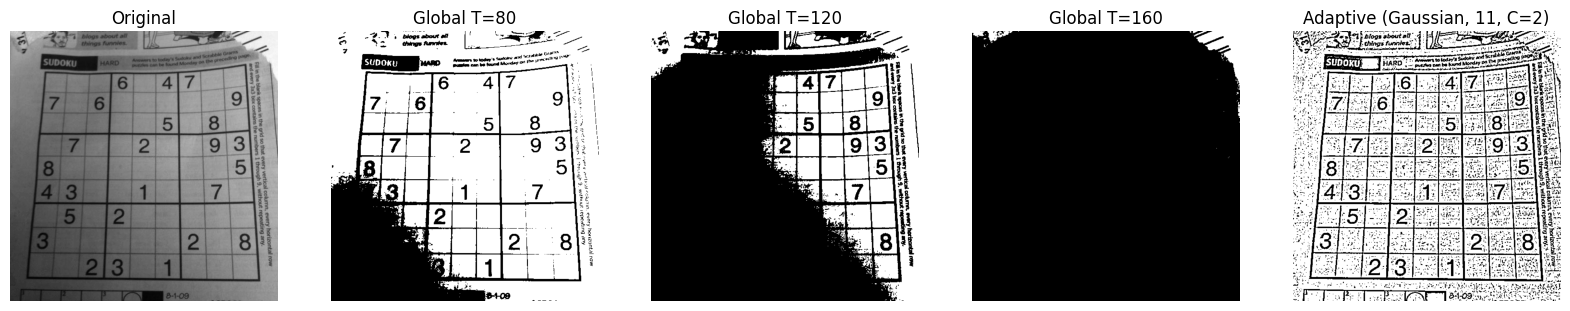

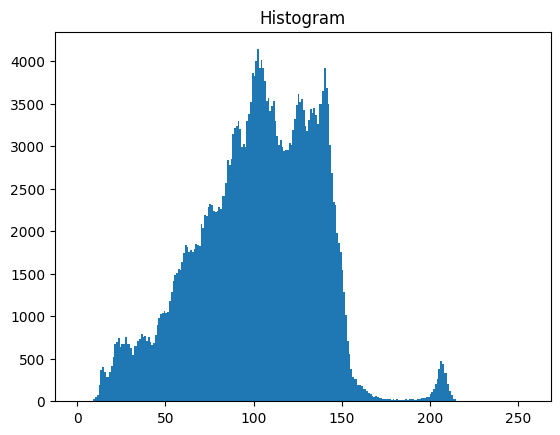

In [17]:
Ts = [80, 120, 160]          # tune after looking at the histogram below
globals_ = [cv2.threshold(gray, t, 255, cv2.THRESH_BINARY)[1] for t in Ts]
adaptive = cv2.adaptiveThreshold(gray, 255, cv2.ADAPTIVE_THRESH_GAUSSIAN_C,
                                 cv2.THRESH_BINARY, 11, 2)

titles = ["Original"] + [f"Global T={t}" for t in Ts] + ["Adaptive (Gaussian, 11, C=2)"]
imgs = [gray] + globals_ + [adaptive]
plt.figure(figsize=(20, 4))
for i, (im, t) in enumerate(zip(imgs, titles)):
    plt.subplot(1, 5, i+1); plt.imshow(im, cmap='gray'); plt.title(t); plt.axis('off')
plt.show()

plt.hist(gray.ravel(), 256, [0, 256]); plt.title("Histogram"); plt.show()

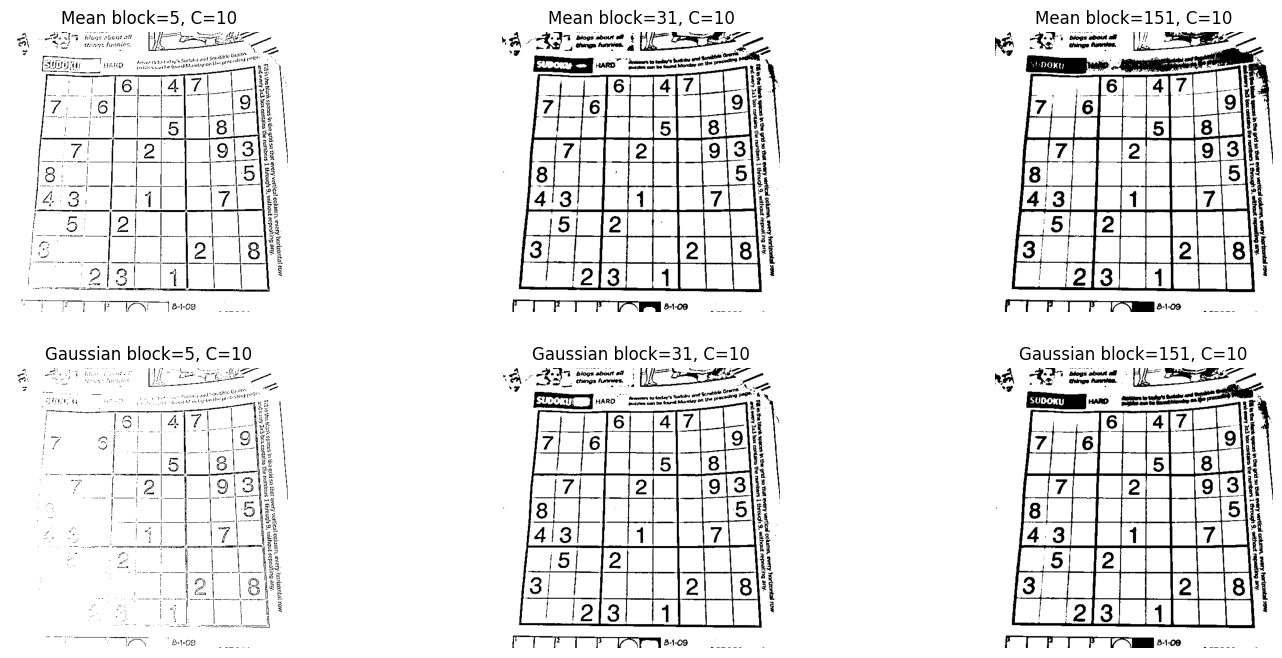

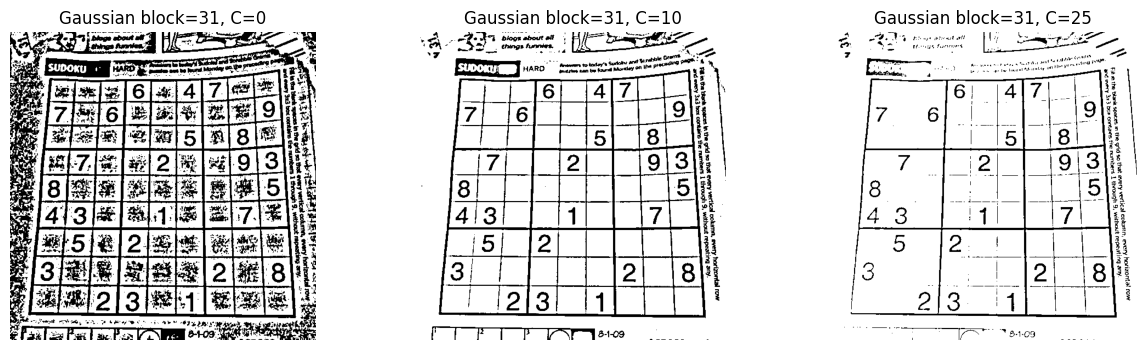

In [18]:
methods = {"Mean": cv2.ADAPTIVE_THRESH_MEAN_C, "Gaussian": cv2.ADAPTIVE_THRESH_GAUSSIAN_C}

plt.figure(figsize=(18, 8))
k = 1
for name, m in methods.items():
    for bs in [5, 31, 151]:
        r = cv2.adaptiveThreshold(gray, 255, m, cv2.THRESH_BINARY, bs, 10)
        plt.subplot(2, 3, k); plt.imshow(r, cmap='gray'); plt.title(f"{name} block={bs}, C=10"); plt.axis('off'); k += 1
plt.show()

plt.figure(figsize=(15, 4))
for i, C in enumerate([0, 10, 25]):
    r = cv2.adaptiveThreshold(gray, 255, cv2.ADAPTIVE_THRESH_GAUSSIAN_C, cv2.THRESH_BINARY, 31, C)
    plt.subplot(1, 3, i+1); plt.imshow(r, cmap='gray'); plt.title(f"Gaussian block=31, C={C}"); plt.axis('off')
plt.show()

Otsu T (original): 96.0 | Otsu T (lower contrast): 107.0


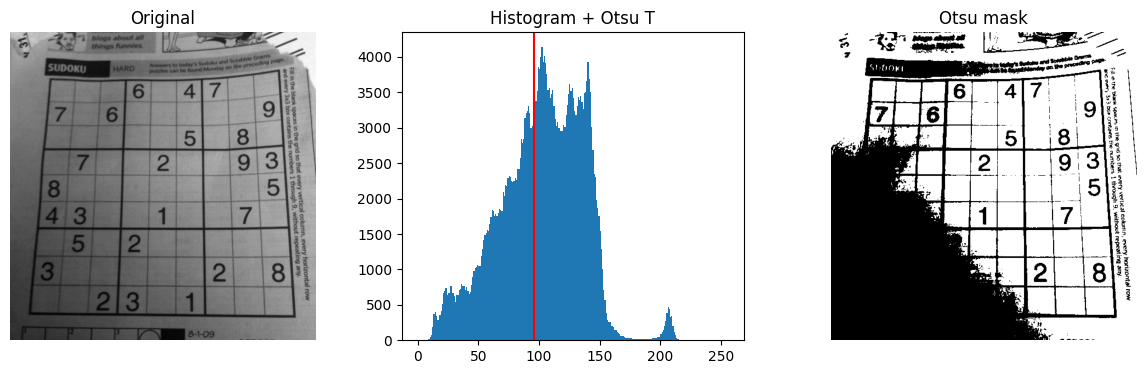

In [19]:
t1, otsu = cv2.threshold(gray, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)

# change contrast slightly and compare
bright = cv2.convertScaleAbs(gray, alpha=0.7, beta=40)
t2, otsu2 = cv2.threshold(bright, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
print("Otsu T (original):", t1, "| Otsu T (lower contrast):", t2)

plt.figure(figsize=(15, 4))
plt.subplot(1, 3, 1); plt.imshow(gray, cmap='gray'); plt.title("Original"); plt.axis('off')
plt.subplot(1, 3, 2); plt.hist(gray.ravel(), 256, [0, 256]); plt.axvline(t1, color='r'); plt.title("Histogram + Otsu T")
plt.subplot(1, 3, 3); plt.imshow(otsu, cmap='gray'); plt.title("Otsu mask"); plt.axis('off')
plt.show()

Otsu T: original=162.0, blurred=162.0, low contrast=127.0


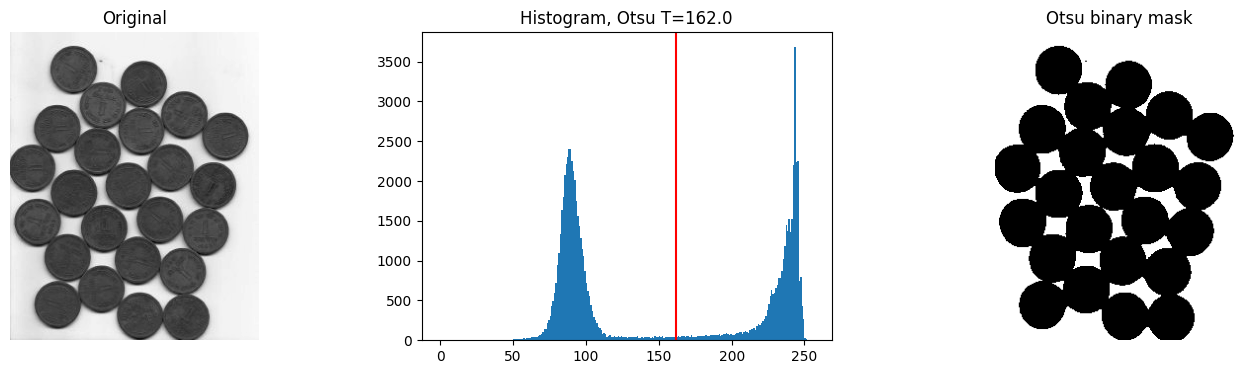

In [20]:
img = cv2.imread('coins.jpg')
if img is None:
    raise FileNotFoundError("coins.jpg not found. Check the filename/path")
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

# Otsu: pass 0 as the threshold, OpenCV computes and returns the real one
t1, otsu1 = cv2.threshold(gray, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)

# Variation: blur slightly (you could also change contrast)
blur = cv2.GaussianBlur(gray, (5, 5), 0)
t2, otsu2 = cv2.threshold(blur, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)

# Variation 2: lower contrast
low = cv2.convertScaleAbs(gray, alpha=0.6, beta=30)
t3, otsu3 = cv2.threshold(low, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)

print(f"Otsu T: original={t1}, blurred={t2}, low contrast={t3}")

plt.figure(figsize=(18, 4))
plt.subplot(1, 3, 1); plt.imshow(gray, cmap='gray'); plt.title("Original"); plt.axis('off')
plt.subplot(1, 3, 2); plt.hist(gray.ravel(), 256, [0, 256]); plt.axvline(t1, color='r'); plt.title(f"Histogram, Otsu T={t1}")
plt.subplot(1, 3, 3); plt.imshow(otsu1, cmap='gray'); plt.title("Otsu binary mask"); plt.axis('off')
plt.show()

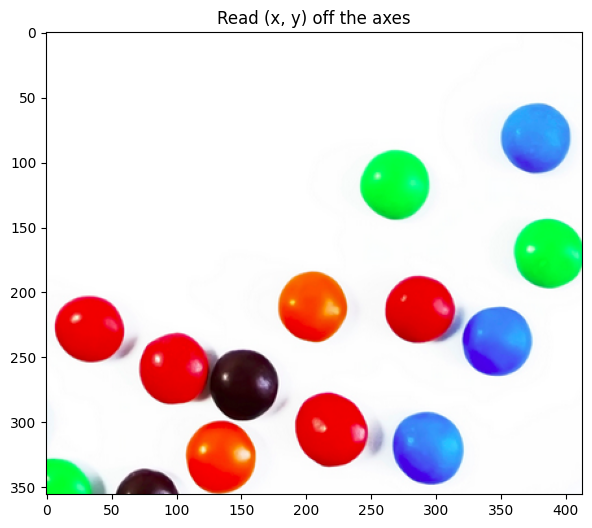

In [22]:
img = cv2.imread('smarties.png')
if img is None:
    raise FileNotFoundError("smarties.png not found. Check the filename/path")
hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)

plt.figure(figsize=(8, 6))
plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB)); plt.axis('on'); plt.title("Read (x, y) off the axes")
plt.show()

In [23]:
y, x = 200, 300          # CHANGE: row, col of a pixel on your chosen candy
print("HSV at that pixel:", hsv[y, x])

HSV at that pixel: [  0 255 238]


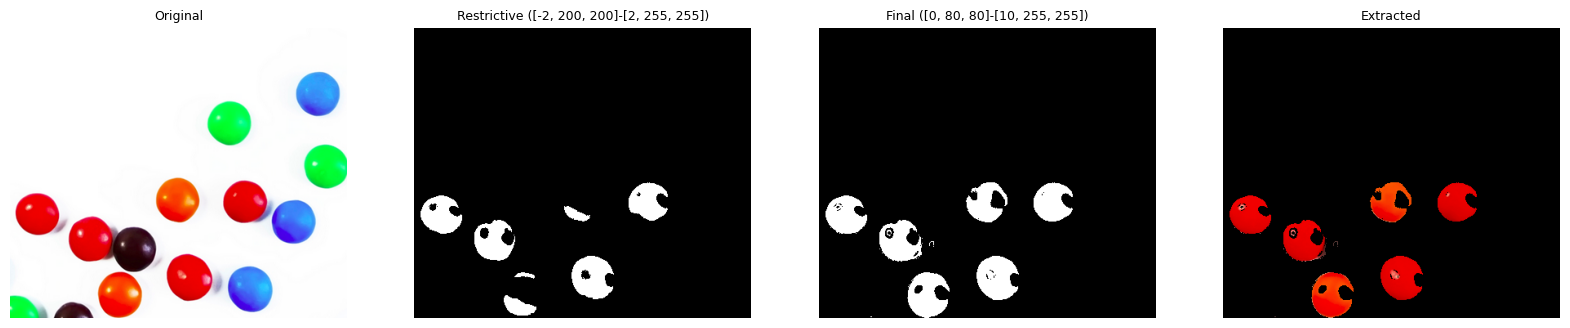

In [24]:
H = int(hsv[y, x][0])    # hue of your chosen candy

# too restrictive: tiny hue window, very high S and V
lower_tight = np.array([H - 2, 200, 200])
upper_tight = np.array([H + 2, 255, 255])
mask_tight = cv2.inRange(hsv, lower_tight, upper_tight)

# final: wider hue window, relaxed S and V
lower_good = np.array([max(H - 10, 0), 80, 80])
upper_good = np.array([min(H + 10, 179), 255, 255])
mask_good = cv2.inRange(hsv, lower_good, upper_good)

extracted = cv2.bitwise_and(img, img, mask=mask_good)

imgs = [cv2.cvtColor(img, cv2.COLOR_BGR2RGB), mask_tight, mask_good, cv2.cvtColor(extracted, cv2.COLOR_BGR2RGB)]
titles = ["Original", f"Restrictive ({lower_tight.tolist()}-{upper_tight.tolist()})",
          f"Final ({lower_good.tolist()}-{upper_good.tolist()})", "Extracted"]
plt.figure(figsize=(20, 4))
for i, (im, t) in enumerate(zip(imgs, titles)):
    plt.subplot(1, 4, i + 1); plt.imshow(im, cmap='gray' if im.ndim == 2 else None); plt.title(t, fontsize=9); plt.axis('off')
plt.show()

Canny 50/100: edge pixels = 3273
Canny 100/200: edge pixels = 2920
Canny 150/250: edge pixels = 2691


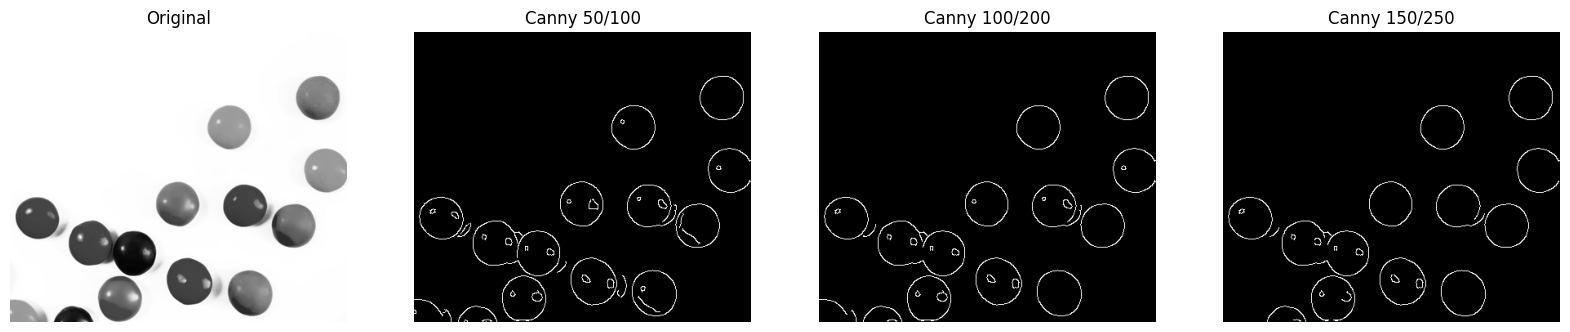

In [26]:
part = cv2.imread('smarties.png', cv2.IMREAD_GRAYSCALE)
if part is None:
    raise FileNotFoundError("smarties.png not found. Check the filename/path")
blur = cv2.GaussianBlur(part, (5, 5), 1.4)

pairs = [(50, 100), (100, 200), (150, 250)]
plt.figure(figsize=(20, 5))
plt.subplot(1, 4, 1); plt.imshow(part, cmap='gray'); plt.title("Original"); plt.axis('off')
for i, (lo, hi) in enumerate(pairs):
    e = cv2.Canny(blur, lo, hi)
    print(f"Canny {lo}/{hi}: edge pixels = {np.count_nonzero(e)}")
    plt.subplot(1, 4, i + 2); plt.imshow(e, cmap='gray'); plt.title(f"Canny {lo}/{hi}"); plt.axis('off')
plt.show()

(388, 371) 0 255


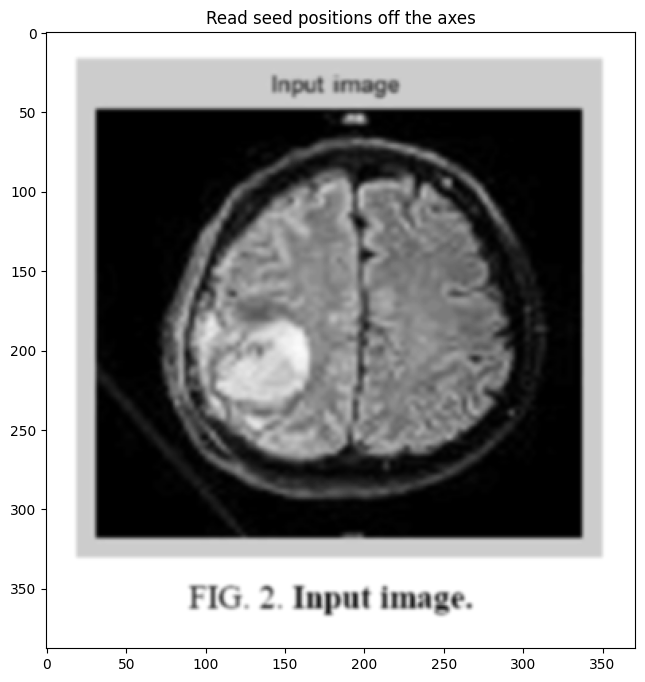

In [27]:
from collections import deque

mri = cv2.imread('brain_mri.png', cv2.IMREAD_GRAYSCALE)   # CHANGE to your filename
if mri is None:
    raise FileNotFoundError("MRI file not found. Check the filename/path")
mri = cv2.GaussianBlur(mri, (5, 5), 0)                    # real MRI is noisy

print(mri.shape, mri.min(), mri.max())
plt.figure(figsize=(8, 8))
plt.imshow(mri, cmap='gray'); plt.axis('on'); plt.title("Read seed positions off the axes")
plt.show()

In [29]:
seedA = (150, 200)    # (row, col): replace with your own spot
seedB = (250, 120)    # a different tissue

print("Seed A intensity:", mri[seedA], "| Seed B intensity:", mri[seedB])

Seed A intensity: 146 | Seed B intensity: 119


Seed A (150, 200), T=10: region size = 190 px
Seed A (150, 200), T=20: region size = 637 px
Seed A (150, 200), T=40: region size = 23039 px
Seed B (250, 120), T=10: region size = 56 px
Seed B (250, 120), T=20: region size = 244 px
Seed B (250, 120), T=40: region size = 21728 px


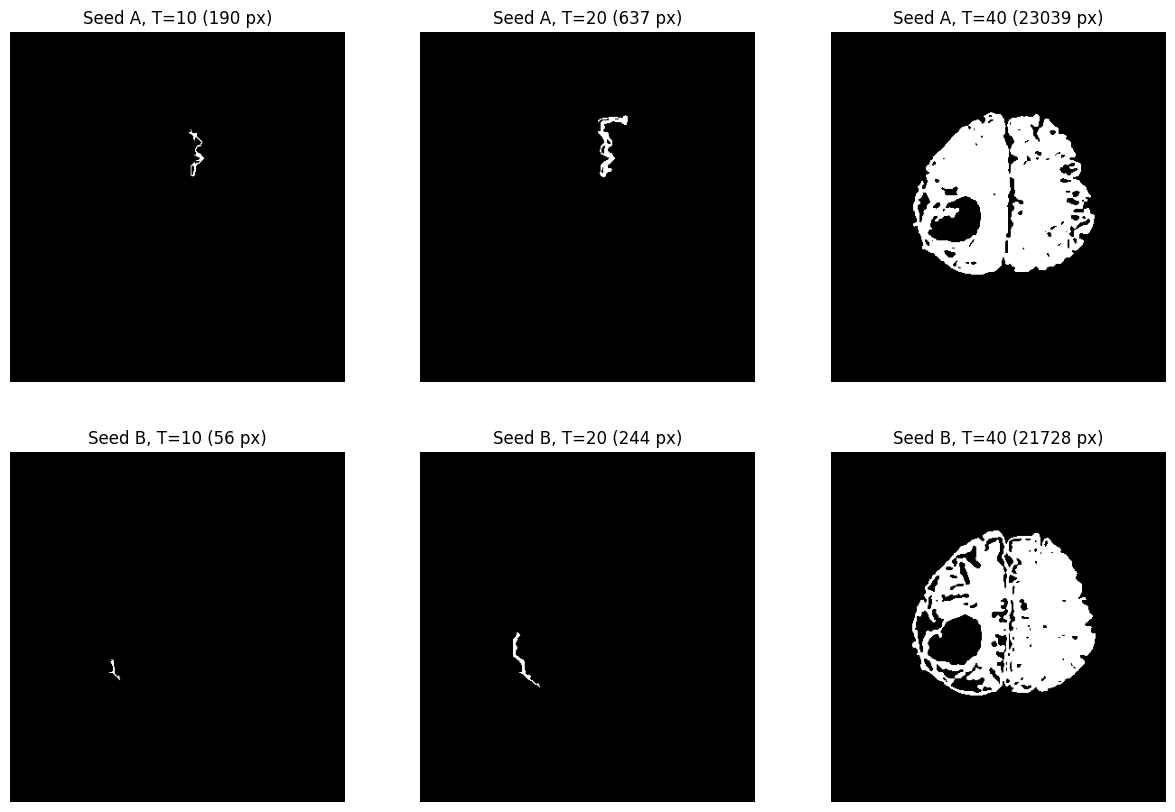

In [30]:
def region_growing(image, seed, thresh):
    """seed = (row, col). Grow through 4-neighbours with |I - I_seed| < thresh."""
    h, w = image.shape
    mask = np.zeros((h, w), np.uint8)
    seed_val = int(image[seed])
    q = deque([seed])
    mask[seed] = 255
    while q:
        r, c = q.popleft()
        for dr, dc in ((1, 0), (-1, 0), (0, 1), (0, -1)):
            nr, nc = r + dr, c + dc
            if 0 <= nr < h and 0 <= nc < w and mask[nr, nc] == 0:
                if abs(int(image[nr, nc]) - seed_val) < thresh:
                    mask[nr, nc] = 255
                    q.append((nr, nc))
    return mask

seeds = {"Seed A": seedA, "Seed B": seedB}
threshs = [10, 20, 40]

plt.figure(figsize=(15, 10))
k = 1
for name, s in seeds.items():
    for t in threshs:
        m = region_growing(mri, s, t)
        area = np.count_nonzero(m)
        print(f"{name} {s}, T={t}: region size = {area} px")
        plt.subplot(2, 3, k); plt.imshow(m, cmap='gray'); plt.title(f"{name}, T={t} ({area} px)"); plt.axis('off'); k += 1
plt.show()

In [31]:
for (r, c) in [(150, 200), (250, 120), (100, 180)]:
    print((r, c), "->", mri[r, c])

(150, 200) -> 146
(250, 120) -> 119
(100, 180) -> 153


In [32]:
coins_real = cv2.imread('coins.jpg')          # CHANGE to your filename
if coins_real is None:
    raise FileNotFoundError("coins image not found. Check the filename/path")

def run_watershed(frac, img, invert=True):
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)                                   # 1 preprocessing
    blur = cv2.GaussianBlur(gray, (5, 5), 0)
    flag = cv2.THRESH_BINARY_INV if invert else cv2.THRESH_BINARY
    _, thresh = cv2.threshold(blur, 0, 255, flag + cv2.THRESH_OTSU)                # 2 thresholding
    kernel = np.ones((3, 3), np.uint8)
    opening = cv2.morphologyEx(thresh, cv2.MORPH_OPEN, kernel, iterations=2)       # 3 noise removal
    sure_bg = cv2.dilate(opening, kernel, iterations=3)                            # 4 sure background
    dist = cv2.distanceTransform(opening, cv2.DIST_L2, 5)                          # 5 distance transform
    _, sure_fg = cv2.threshold(dist, frac * dist.max(), 255, 0)                    # 6 sure foreground
    sure_fg = np.uint8(sure_fg)
    unknown = cv2.subtract(sure_bg, sure_fg)                                       # 7 unknown region
    n, markers = cv2.connectedComponents(sure_fg)                                  # 8 marker labeling
    markers = markers + 1                                                          # background = 1, not 0
    markers[unknown == 255] = 0                                                    # 0 = let watershed decide
    out = img.copy()
    markers = cv2.watershed(out, markers)                                          # 9 watershed
    out[markers == -1] = (0, 0, 255)                                               # 10 boundaries in red
    regions = len(np.unique(markers)) - 2                                          # minus boundary (-1) and background (1)
    return dict(thresh=thresh, sure_bg=sure_bg, dist=dist, sure_fg=sure_fg,
                unknown=unknown, out=out, markers=n - 1, regions=regions)

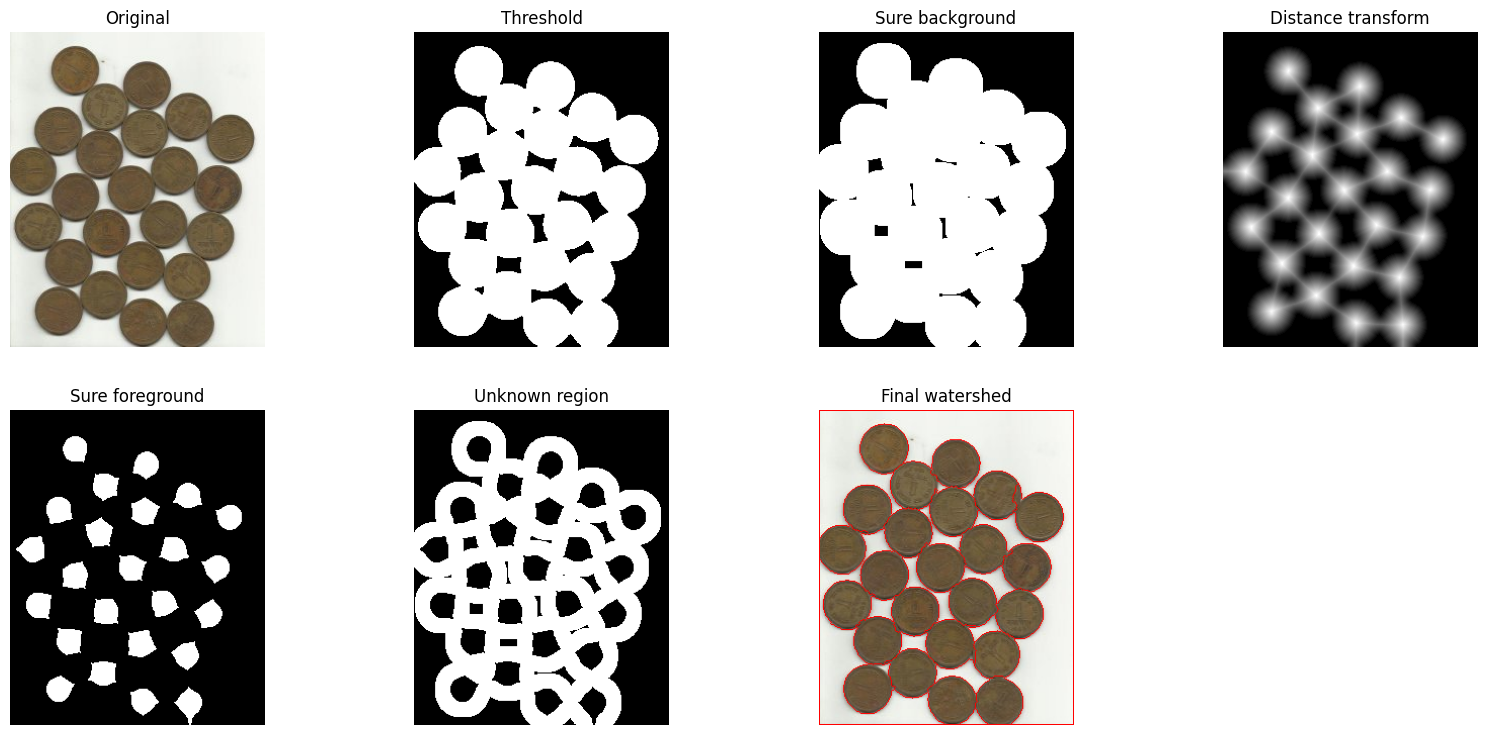

Blobs in plain threshold: 1 | watershed regions: 24


True

In [34]:
r = run_watershed(0.5, coins_real)
dist_vis = cv2.normalize(r["dist"], None, 0, 255, cv2.NORM_MINMAX).astype(np.uint8)
stages = [("Original", cv2.cvtColor(coins_real, cv2.COLOR_BGR2RGB)), ("Threshold", r["thresh"]),
          ("Sure background", r["sure_bg"]), ("Distance transform", dist_vis),
          ("Sure foreground", r["sure_fg"]), ("Unknown region", r["unknown"]),
          ("Final watershed", cv2.cvtColor(r["out"], cv2.COLOR_BGR2RGB))]
plt.figure(figsize=(20, 9))
for i, (t, im) in enumerate(stages):
    plt.subplot(2, 4, i + 1); plt.imshow(im, cmap=None if im.ndim == 3 else 'gray'); plt.title(t); plt.axis('off')
plt.show()
print("Blobs in plain threshold:", cv2.connectedComponents(r["thresh"])[0] - 1,
      "| watershed regions:", r["regions"])
cv2.imwrite('task7_result.png', r["out"])

Exp  Dist thresh (x max)   FG markers   Regions  
1    0.1                   1            1        
2    0.3                   1            1        
3    0.5                   24           24       
4    0.7                   24           24       
5    0.9                   24           24       


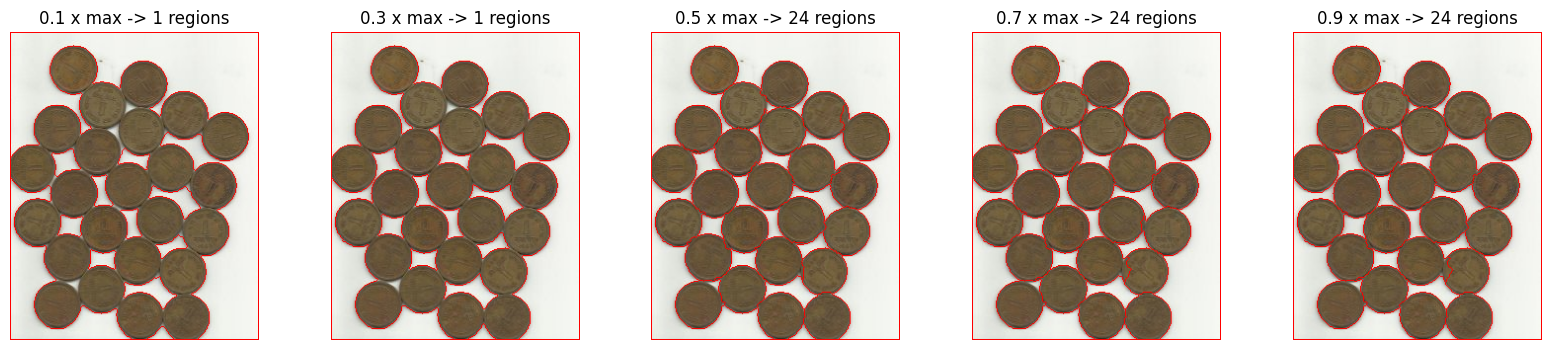

In [35]:
print(f"{'Exp':<5}{'Dist thresh (x max)':<22}{'FG markers':<13}{'Regions':<9}")
fracs = [0.1, 0.3, 0.5, 0.7, 0.9]
plt.figure(figsize=(20, 4))
for i, f in enumerate(fracs):
    r = run_watershed(f, coins_real)
    print(f"{i+1:<5}{f:<22}{r['markers']:<13}{r['regions']:<9}")
    plt.subplot(1, 5, i + 1); plt.imshow(cv2.cvtColor(r["out"], cv2.COLOR_BGR2RGB))
    plt.title(f"{f} x max -> {r['regions']} regions"); plt.axis('off')
plt.show()

Original shape: (350, 233, 3)
K=2: distinct colors = 2
Cluster centers (BGR):
 [[140 146 178]
 [ 60  67  91]]
K=4: distinct colors = 4
Cluster centers (BGR):
 [[ 71  85 117]
 [114 123 165]
 [181 180 198]
 [ 54  57  76]]
K=6: distinct colors = 6
Cluster centers (BGR):
 [[116 129 193]
 [152 144 158]
 [190 190 206]
 [ 86 102 137]
 [ 63  75 105]
 [ 53  55  72]]


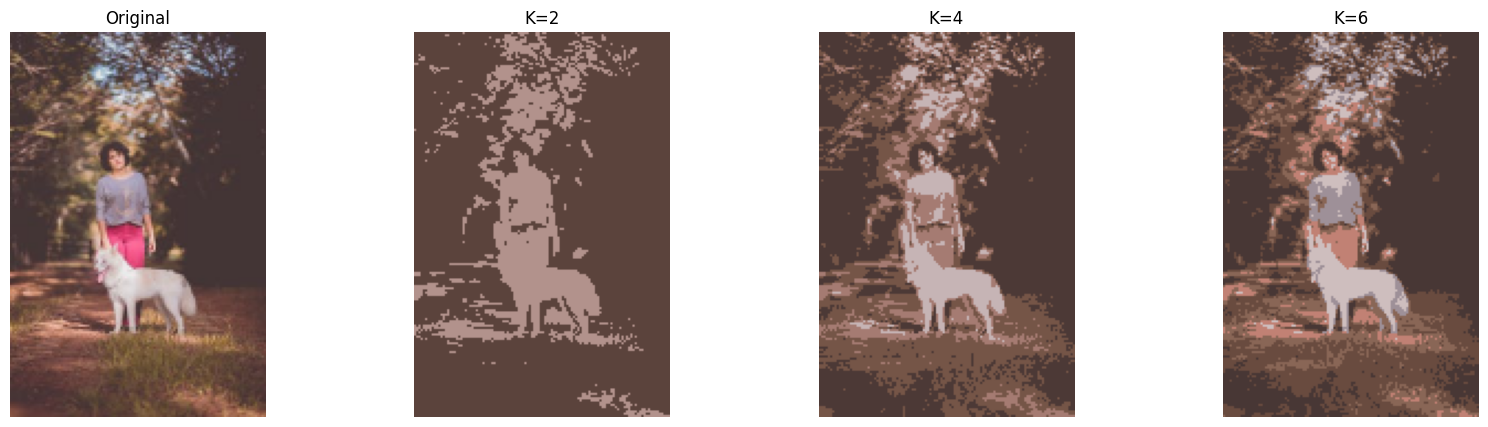

In [36]:
photo = cv2.imread('dog.jpeg')
if photo is None:
    raise FileNotFoundError("dog.jpeg not found. Check the filename/path")
print("Original shape:", photo.shape)
photo = cv2.resize(photo, None, fx=0.5, fy=0.5)   # skip this line if the image is already small

pixels = photo.reshape(-1, 3).astype(np.float32)
criteria = (cv2.TERM_CRITERIA_EPS + cv2.TERM_CRITERIA_MAX_ITER, 100, 0.2)

plt.figure(figsize=(20, 5))
plt.subplot(1, 4, 1); plt.imshow(cv2.cvtColor(photo, cv2.COLOR_BGR2RGB)); plt.title("Original"); plt.axis('off')
for i, K in enumerate([2, 4, 6]):
    _, labels, centers = cv2.kmeans(pixels, K, None, criteria, 10, cv2.KMEANS_RANDOM_CENTERS)
    seg = np.uint8(centers)[labels.flatten()].reshape(photo.shape)
    print(f"K={K}: distinct colors = {len(np.unique(seg.reshape(-1, 3), axis=0))}")
    print("Cluster centers (BGR):\n", np.uint8(centers))
    plt.subplot(1, 4, i + 2); plt.imshow(cv2.cvtColor(seg, cv2.COLOR_BGR2RGB)); plt.title(f"K={K}"); plt.axis('off')
    cv2.imwrite(f'task9_K{K}.png', seg)
plt.show()

## Task 9: K-Means Segmentation Results

| K | Clusters | Visual difference from original | Color simplification | Major regions represented |
|---|---|---|---|---|
| 2 | 2 | Heavy loss of detail; image reduced to a light/dark split | Thousands of colors reduced to 2 | Bright areas vs dark areas / shadows |
| 4 | 4 | Main structure visible; shading becomes banded | Reduced to 4 | (fill in from your plot: e.g. dark fur/shadow, mid-tone body, light background) |
| 6 | 6 | Closest to the original; finer shading and smaller regions appear | Reduced to 6 | (fill in from your plot) |

**Observation:** The centers differ mostly in brightness and share a warm (red-dominant) hue, so K-means mainly divides this image by lightness. K-means uses color only, not pixel position, so separate areas of similar color end up in the same cluster.

Otsu threshold: 108.0
Canny edge pixels: 2454


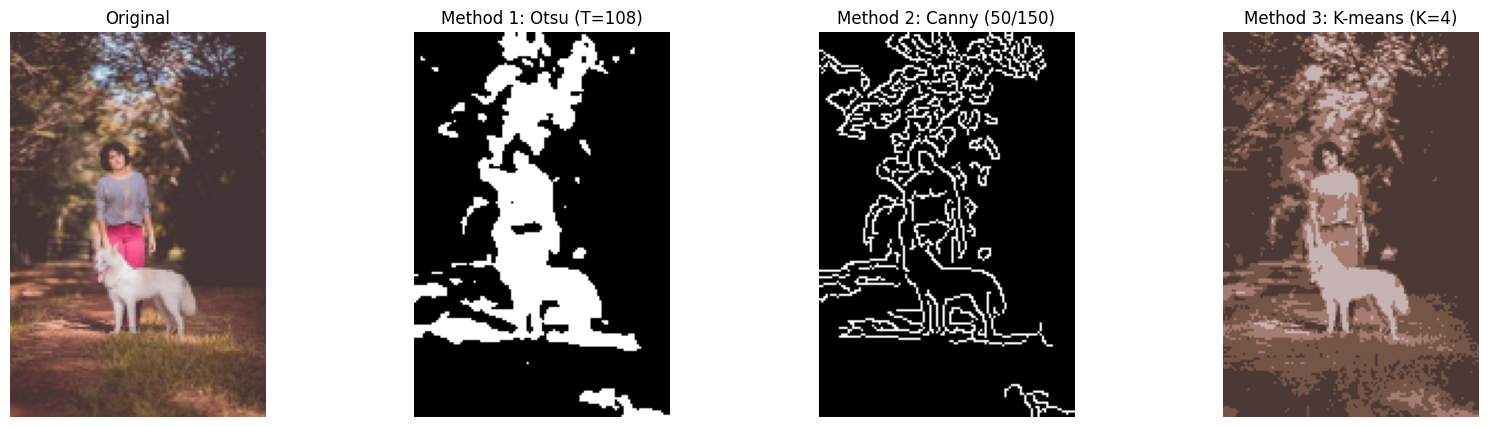

True

In [37]:
img = cv2.imread('dog.jpeg')
if img is None:
    raise FileNotFoundError("dog.jpeg not found. Check the filename/path")
img = cv2.resize(img, None, fx=0.5, fy=0.5)
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
blur = cv2.GaussianBlur(gray, (5, 5), 0)

# Method 1: Otsu
t_otsu, m_otsu = cv2.threshold(blur, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)

# Method 2: Canny
m_canny = cv2.Canny(blur, 50, 150)

# Method 3: K-means (K=4)
pixels = img.reshape(-1, 3).astype(np.float32)
criteria = (cv2.TERM_CRITERIA_EPS + cv2.TERM_CRITERIA_MAX_ITER, 100, 0.2)
_, labels, centers = cv2.kmeans(pixels, 4, None, criteria, 10, cv2.KMEANS_RANDOM_CENTERS)
m_kmeans = np.uint8(centers)[labels.flatten()].reshape(img.shape)

print("Otsu threshold:", t_otsu)
print("Canny edge pixels:", np.count_nonzero(m_canny))

results = [("Original", cv2.cvtColor(img, cv2.COLOR_BGR2RGB)),
           (f"Method 1: Otsu (T={t_otsu:.0f})", m_otsu),
           ("Method 2: Canny (50/150)", m_canny),
           ("Method 3: K-means (K=4)", cv2.cvtColor(m_kmeans, cv2.COLOR_BGR2RGB))]
plt.figure(figsize=(20, 5))
for i, (t, im) in enumerate(results):
    plt.subplot(1, 4, i + 1); plt.imshow(im, cmap=None if im.ndim == 3 else 'gray'); plt.title(t); plt.axis('off')
plt.show()

cv2.imwrite('task10_otsu.png', m_otsu)
cv2.imwrite('task10_canny.png', m_canny)
cv2.imwrite('task10_kmeans.png', m_kmeans)

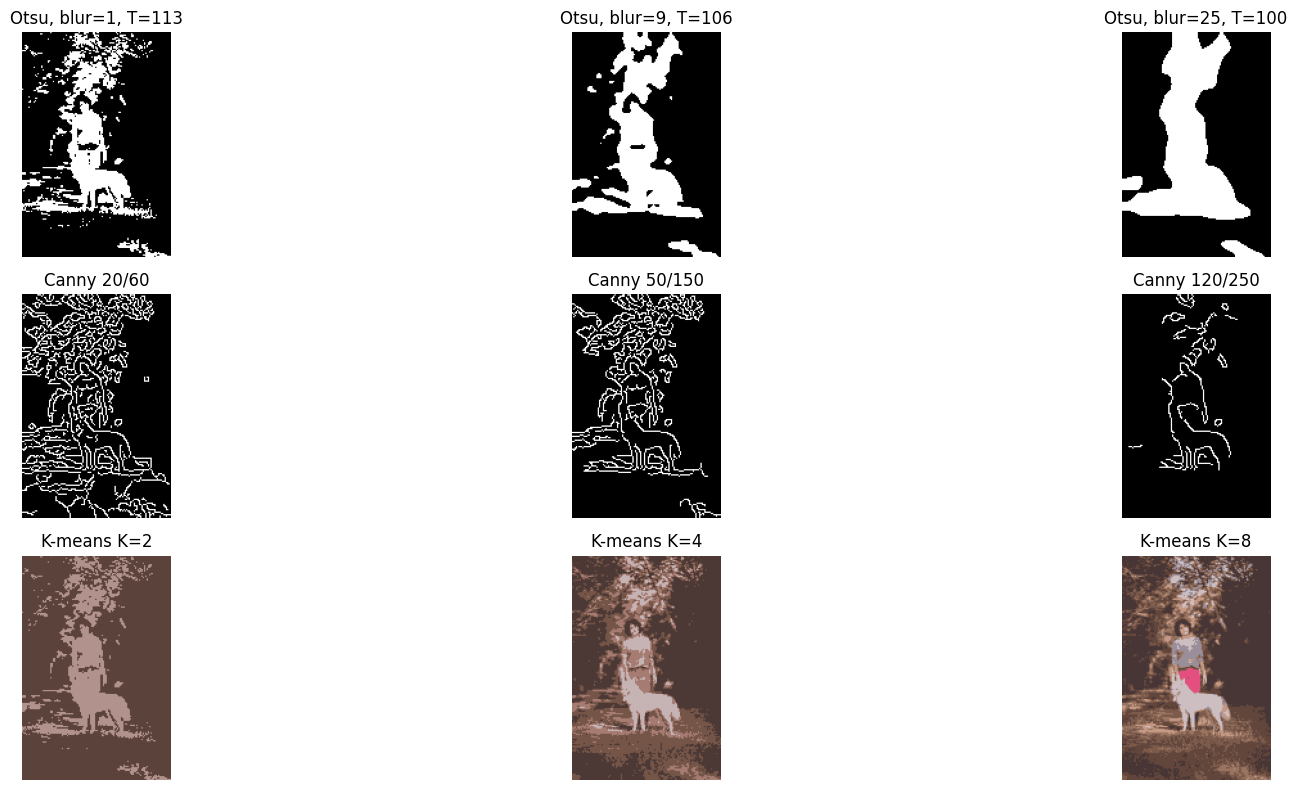

In [38]:
plt.figure(figsize=(20, 8))
# Otsu: effect of blur (preprocessing) on the threshold
for i, k in enumerate([1, 9, 25]):
    b = cv2.GaussianBlur(gray, (k, k), 0)
    t, m = cv2.threshold(b, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
    plt.subplot(3, 3, i + 1); plt.imshow(m, cmap='gray'); plt.title(f"Otsu, blur={k}, T={t:.0f}"); plt.axis('off')
# Canny: effect of thresholds
for i, (lo, hi) in enumerate([(20, 60), (50, 150), (120, 250)]):
    plt.subplot(3, 3, 4 + i); plt.imshow(cv2.Canny(blur, lo, hi), cmap='gray'); plt.title(f"Canny {lo}/{hi}"); plt.axis('off')
# K-means: effect of K
for i, K in enumerate([2, 4, 8]):
    _, lab, cen = cv2.kmeans(pixels, K, None, criteria, 10, cv2.KMEANS_RANDOM_CENTERS)
    seg = np.uint8(cen)[lab.flatten()].reshape(img.shape)
    plt.subplot(3, 3, 7 + i); plt.imshow(cv2.cvtColor(seg, cv2.COLOR_BGR2RGB)); plt.title(f"K-means K={K}"); plt.axis('off')
plt.tight_layout(); plt.show()

## Task 10: Segmentation System for dog.jpeg

| | Otsu Thresholding | Canny Edge Detection | K-Means (K=4) |
|---|---|---|---|
| **Assumption** | Histogram is bimodal: one intensity class for object, one for background | Object boundaries are sharp intensity changes | Regions differ in color, and pixels of a region have similar color |
| **Successfully identifies** | [e.g. the dark/shadowed areas vs the lighter areas] | [e.g. the dog's outline and strong fur/background boundaries] | [e.g. main color regions: dark fur, mid-tone body, light background] |
| **Incorrectly segments** | [e.g. fur and background of similar brightness end up in the same class] | [e.g. fur texture produces many unwanted edges; outline is not filled] | [e.g. separate areas of similar color are merged into one cluster] |
| **Most influential parameter** | Preprocessing (blur) / image contrast, since T is derived from the histogram | The low/high thresholds | K (number of clusters) |

### Conclusion

[Name the method that gave the most meaningful regions, based on your plots.] This was suitable because [the property of dog.jpeg that made it work, e.g. the dog and background differ mainly in color rather than sharp, clean edges / the image has strong brightness contrast between subject and background].